# YZM 411 Bilgisayarlı Görü — Ödev 1: Renk, Aydınlatma ve Örnekleme

**Emiralp Boyunaga — 230212042**

## Kütüphaneler

In [ ]:
import os, sys, platform
import numpy as np
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

if "__vsc_ipynb_file__" in globals():
    os.chdir(os.path.dirname(__vsc_ipynb_file__))
print("Çalışma klasörü:", os.getcwd())

os.makedirs("sonuclar", exist_ok=True)

print("Python    :", platform.python_version())
print("NumPy     :", np.__version__)
print("OpenCV    :", cv2.__version__)
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)

Çalışma klasörü: c:\Users\eboyu\Desktop\Proje
Python    : 3.11.9
NumPy     : 2.4.4
OpenCV    : 4.12.0
pandas    : 2.3.3
matplotlib: 3.10.8


## Parametreler
Tüm ayarlanabilir değerler burada.

In [ ]:
DOSYALAR = {
    "normal": "normal.jpg",
    "golge":  "golge.jpg",
    "lamba":  "lamba.jpg",
}

PIKSELLER = {
    "normal": [(1300, 1100), (620, 600), (1790, 890)],
    "golge":  [(1180, 960),  (640, 560), (1670, 780)],
    "lamba":  [(1200, 1080), (600, 580), (1620, 880)],
}

NESNE_ROI = {
    "normal": (1350, 600, 100, 100),
    "golge":  (1230, 595, 100, 100),
    "lamba":  (1250, 580, 100, 100),
}

ARABA_KUTU = {
    "normal": (475, 15, 1840, 1190),
    "golge":  (560, 115, 1560, 880),
    "lamba":  (476, 50, 1690, 1115),
}

RGB_ALT = (0, 65, 113)
RGB_UST = (60, 150, 200)
HSV_ALT = (97, 177, 113)
HSV_UST = (106, 255, 255)

SARI_ALT = (12, 60, 80)
SARI_UST = (22, 255, 255)
YUZ_ROI = {
    "normal": (1772, 772, 30, 30),
    "golge":  (1674, 672, 30, 30),
    "lamba":  (1615, 757, 30, 30),
}

B_KAYMA = 40
GAMALAR = [0.5, 2.0]

YAZI_BOLGE = (1680, 905, 240, 100)
OLCEK = 4

## 1. Görüntünün sayısal yapısı

In [ ]:
import glob, unicodedata

def bul(ad):
    hedef = {"golge": ["golge", "gölge"]}.get(ad, [ad])
    for f in os.listdir():
        govde = unicodedata.normalize("NFC", f.lower()).split(".")[0]
        if govde in hedef and f.lower().endswith((".jpg", ".jpeg")):
            return f
    raise FileNotFoundError(f"{ad} için fotoğraf bulunamadı. Klasördekiler: {os.listdir()}")

bgr = {}
rgb = {}
for ad in DOSYALAR:
    dosya = bul(ad)
    img = cv2.imdecode(np.fromfile(dosya, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"{dosya} bulundu ama okunamadı (JPEG değil olabilir).")
    print(f"{ad:7s} <- {dosya}")
    if img.shape[1] != 2576:
        raise ValueError(f"{dosya} genişliği {img.shape[1]} px; 2576 px olan özgün fotoğrafı kullanın "
                         "(WhatsApp vb. ile gönderilen fotoğraflar küçültülür).")
    bgr[ad] = img
    rgb[ad] = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for ad, img in rgb.items():
    print(f"{ad:7s} shape={img.shape}  (H x W x C)  dtype={img.dtype}  min={img.min()}  max={img.max()}")

normal  <- normal.jpg
golge   <- golge.jpg
lamba   <- lamba.jpg
normal  shape=(1279, 2576, 3)  (H x W x C)  dtype=uint8  min=0  max=255
golge   shape=(1142, 2576, 3)  (H x W x C)  dtype=uint8  min=0  max=247
lamba   shape=(1261, 2576, 3)  (H x W x C)  dtype=uint8  min=0  max=255


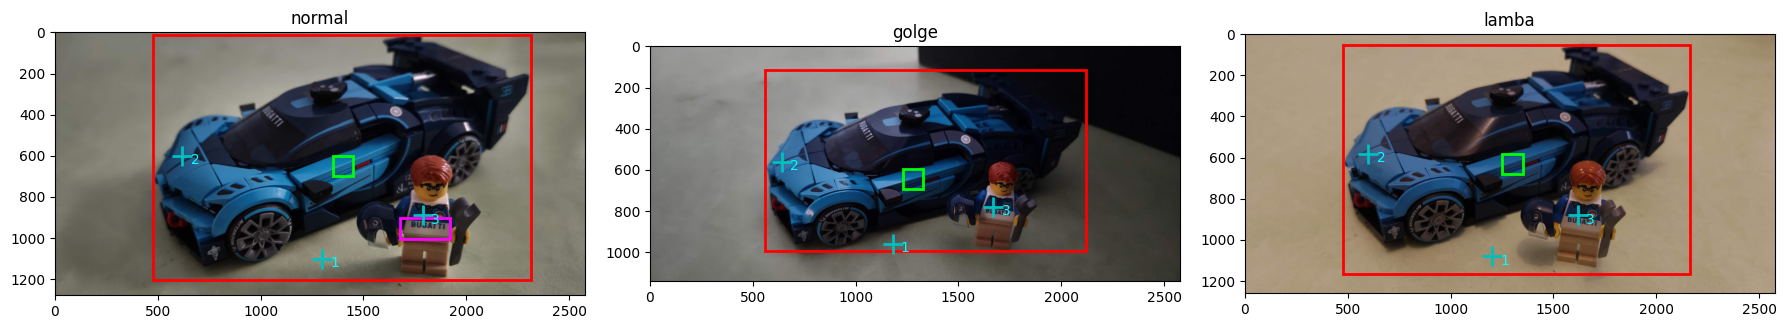

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, (ad, img) in enumerate(rgb.items()):
    ax[i].imshow(img)
    ax[i].set_title(ad)
    for k, (x, y) in enumerate(PIKSELLER[ad], start=1):
        ax[i].plot(x, y, "c+", markersize=14, mew=2)
        ax[i].annotate(str(k), (x, y), xytext=(6, -6), textcoords="offset points", color="cyan")
    x, y, w, h = ARABA_KUTU[ad]
    ax[i].add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="red", lw=2))
    x, y, w, h = NESNE_ROI[ad]
    ax[i].add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="lime", lw=2))
    if ad == "normal":
        x, y, w, h = YAZI_BOLGE
        ax[i].add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="magenta", lw=2))
plt.tight_layout()
plt.savefig("sonuclar/ozgun_fotograflar.png", dpi=120)
plt.show()

In [5]:
x, y = PIKSELLER["normal"][0]
print(f"Piksel (x={x}, y={y})")
print("  BGR (cv2.imread)  :", bgr["normal"][y, x])
print("  RGB (dönüştürülmüş):", rgb["normal"][y, x])
print("  Yalnızca R kanalı : rgb['normal'][y, x, 0] =", rgb["normal"][y, x, 0])
print("  BGR'de R kanalı   : bgr['normal'][y, x, 2] =", bgr["normal"][y, x, 2])

Piksel (x=1300, y=1100)
  BGR (cv2.imread)  : [129 148 151]
  RGB (dönüştürülmüş): [151 148 129]
  Yalnızca R kanalı : rgb['normal'][y, x, 0] = 151
  BGR'de R kanalı   : bgr['normal'][y, x, 2] = 151


In [6]:
satirlar = []
for k in range(len(PIKSELLER["normal"])):
    satir = {"nokta": k + 1}
    for ad, img in rgb.items():
        x, y = PIKSELLER[ad][k]
        r, g, b = img[y, x]
        satir[f"{ad} (x, y)"] = f"({x}, {y})"
        satir[ad] = f"({r}, {g}, {b})"
    satirlar.append(satir)
piksel_tablo = pd.DataFrame(satirlar)
piksel_tablo.to_csv("sonuclar/piksel_degerleri.csv", index=False)
piksel_tablo

,nokta,"normal (x, y)",normal,"golge (x, y)",golge,"lamba (x, y)",lamba
0,1,"(1300, 1100)","(151, 148, 129)","(1180, 960)","(91, 88, 81)","(1200, 1080)","(159, 140, 108)"
1,2,"(620, 600)","(35, 83, 121)","(640, 560)","(56, 82, 119)","(600, 580)","(61, 93, 134)"
2,3,"(1790, 890)","(10, 35, 66)","(1670, 780)","(10, 30, 65)","(1620, 880)","(17, 34, 62)"


In [ ]:
from PIL import Image, ExifTags
for ad, dosya in DOSYALAR.items():
    try:
        exif = Image.open(dosya).getexif()
        ifd = exif.get_ifd(0x8769)
        tags = {ExifTags.TAGS.get(k, k): v for k, v in {**exif, **ifd}.items()}
        print(ad, {k: tags.get(k) for k in ["ExposureTime", "ISOSpeedRatings", "ExposureMode", "WhiteBalance"]})
    except Exception as e:
        print(ad, "EXIF okunamadı:", e)

normal {'ExposureTime': None, 'ISOSpeedRatings': None, 'ExposureMode': None, 'WhiteBalance': None}
golge {'ExposureTime': None, 'ISOSpeedRatings': None, 'ExposureMode': None, 'WhiteBalance': None}
lamba {'ExposureTime': None, 'ISOSpeedRatings': None, 'ExposureMode': None, 'WhiteBalance': None}


## 2. Sabit renk eşikleri

In [8]:
x, y, w, h = NESNE_ROI["normal"]
roi_rgb = rgb["normal"][y:y+h, x:x+w].reshape(-1, 3)
roi_hsv = cv2.cvtColor(bgr["normal"], cv2.COLOR_BGR2HSV)[y:y+h, x:x+w].reshape(-1, 3)

istat = pd.DataFrame({
    "kanal": ["R", "G", "B", "H", "S", "V"],
    "p5":  np.r_[np.percentile(roi_rgb, 5, axis=0),  np.percentile(roi_hsv, 5, axis=0)],
    "medyan": np.r_[np.median(roi_rgb, axis=0),     np.median(roi_hsv, axis=0)],
    "p95": np.r_[np.percentile(roi_rgb, 95, axis=0), np.percentile(roi_hsv, 95, axis=0)],
}).round(1)
print("Bu değerlere bakarak Parametreler hücresindeki eşikleri BİR KEZ belirleyin.")
print("Not: Kırmızı nesnelerde H 0 ve 179 etrafında dolanır.")
istat

Bu değerlere bakarak Parametreler hücresindeki eşikleri BİR KEZ belirleyin.
Not: Kırmızı nesnelerde H 0 ve 179 etrafında dolanır.


,kanal,p5,medyan,p95
0,R,10.0,22.0,50.0
1,G,75.0,112.0,140.0
2,B,123.0,165.0,190.0
3,H,100.0,101.0,103.0
4,S,187.0,221.0,237.0
5,V,123.0,165.0,190.0


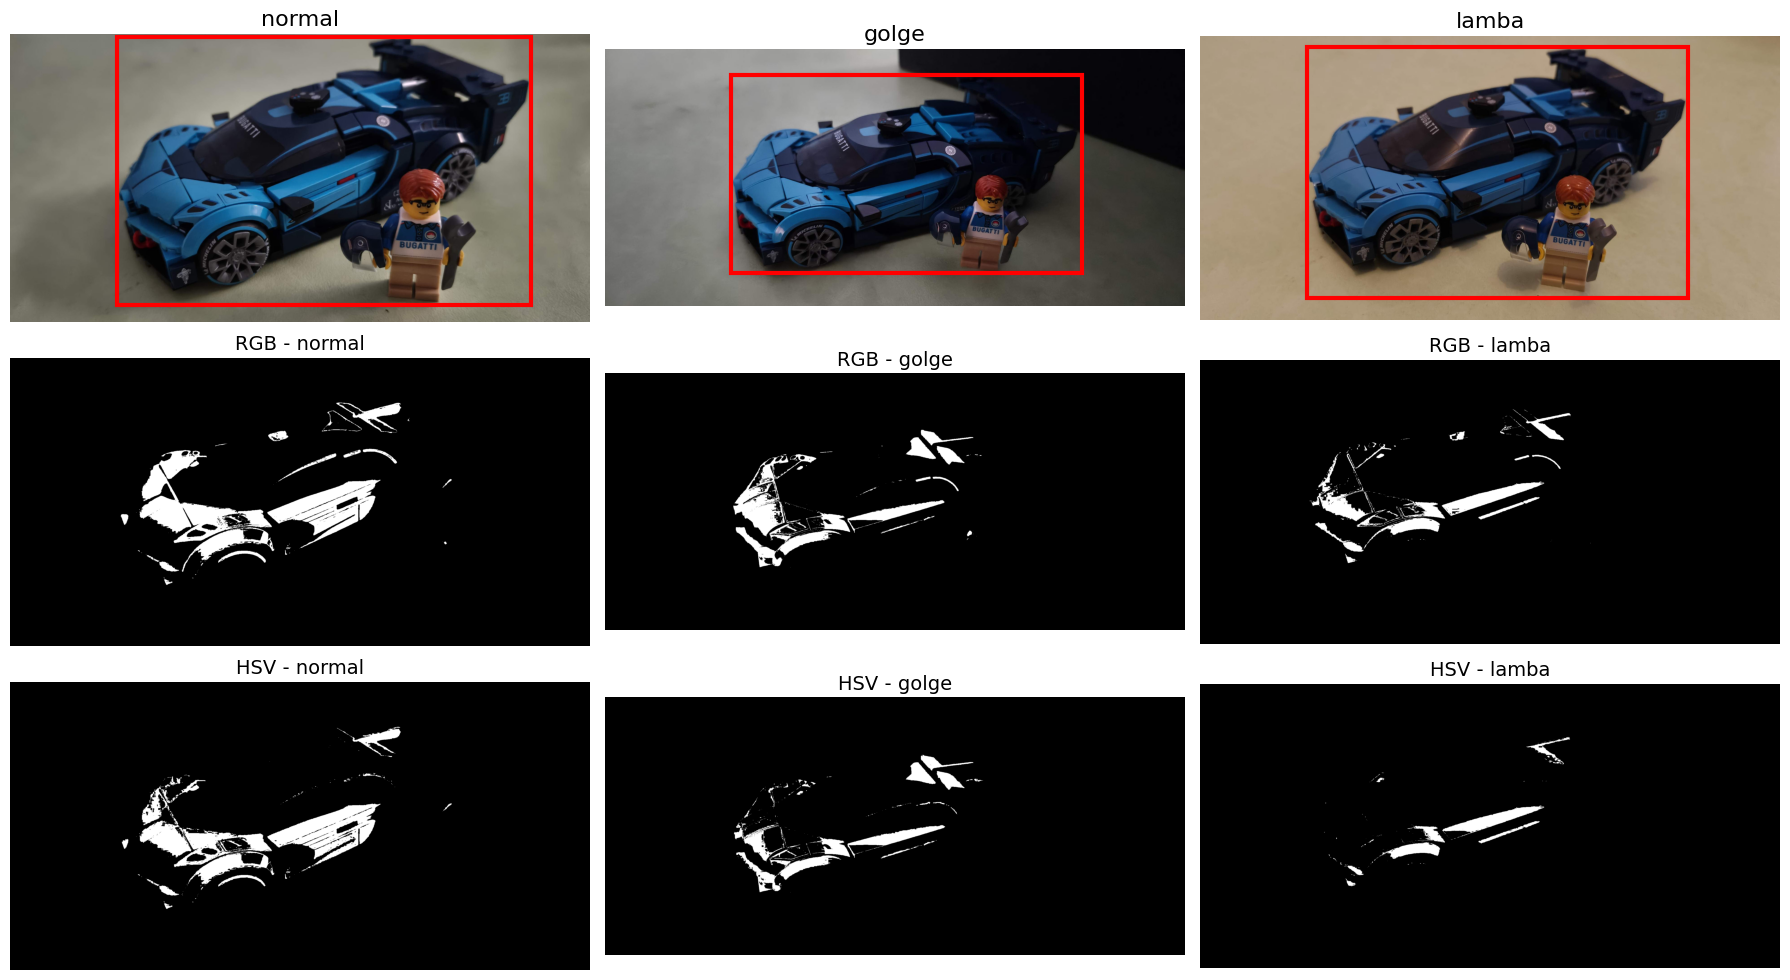

,fotograf,RGB_secilen_piksel,RGB_alan_%,HSV_secilen_piksel,HSV_alan_%
0,normal,180900,5.49,147866,4.49
1,golge,98328,3.34,70867,2.41
2,lamba,78740,2.42,41002,1.26


In [ ]:
def rgb_maske(img_rgb):
    return cv2.inRange(img_rgb, np.array(RGB_ALT), np.array(RGB_UST))

def hsv_maske(img_bgr):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv, np.array(HSV_ALT), np.array(HSV_UST))

maske_sonuc = []
fig, ax = plt.subplots(3, 3, figsize=(18, 10))
for i, ad in enumerate(DOSYALAR):
    m_rgb = rgb_maske(rgb[ad])
    m_hsv = hsv_maske(bgr[ad])
    oran_rgb = 100 * np.count_nonzero(m_rgb) / m_rgb.size
    oran_hsv = 100 * np.count_nonzero(m_hsv) / m_hsv.size
    maske_sonuc.append({"fotograf": ad,
                        "RGB_secilen_piksel": int(np.count_nonzero(m_rgb)), "RGB_alan_%": round(oran_rgb, 2),
                        "HSV_secilen_piksel": int(np.count_nonzero(m_hsv)), "HSV_alan_%": round(oran_hsv, 2)})
    cv2.imwrite(f"sonuclar/maske_rgb_{ad}.png", m_rgb)
    cv2.imwrite(f"sonuclar/maske_hsv_{ad}.png", m_hsv)
    ax[0, i].imshow(rgb[ad]); ax[0, i].set_title(ad, fontsize=16)
    x, y, w, h = ARABA_KUTU[ad]
    ax[0, i].add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="red", lw=3))
    ax[1, i].imshow(m_rgb, cmap="gray"); ax[1, i].set_title(f"RGB - {ad}", fontsize=14)
    ax[2, i].imshow(m_hsv, cmap="gray"); ax[2, i].set_title(f"HSV - {ad}", fontsize=14)
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig("sonuclar/alti_maske.png", dpi=120)
plt.show()

maske_tablo = pd.DataFrame(maske_sonuc)
maske_tablo.to_csv("sonuclar/maske_oranlari.csv", index=False)
maske_tablo

In [ ]:
roi_sonuc = []
for ad in DOSYALAR:
    x, y, w, h = NESNE_ROI[ad]
    m_rgb = rgb_maske(rgb[ad])[y:y+h, x:x+w]
    m_hsv = hsv_maske(bgr[ad])[y:y+h, x:x+w]
    med_rgb = np.median(rgb[ad][y:y+h, x:x+w].reshape(-1, 3), axis=0).astype(int)
    med_hsv = np.median(cv2.cvtColor(bgr[ad], cv2.COLOR_BGR2HSV)[y:y+h, x:x+w].reshape(-1, 3), axis=0).astype(int)
    zx, zy = PIKSELLER[ad][0]
    roi_sonuc.append({"fotograf": ad,
                      "ROI_medyan_RGB": tuple(int(v) for v in med_rgb),
                      "ROI_medyan_HSV": tuple(int(v) for v in med_hsv),
                      "ROI_ici_RGB_%": round(100*np.count_nonzero(m_rgb)/m_rgb.size, 1),
                      "ROI_ici_HSV_%": round(100*np.count_nonzero(m_hsv)/m_hsv.size, 1),
                      "zemin_RGB": tuple(int(v) for v in rgb[ad][zy, zx])})
roi_tablo = pd.DataFrame(roi_sonuc)
maske_tablo = maske_tablo.merge(roi_tablo, on="fotograf")
maske_tablo.to_csv("sonuclar/maske_oranlari.csv", index=False)
maske_tablo

,fotograf,RGB_secilen_piksel,RGB_alan_%,HSV_secilen_piksel,HSV_alan_%,ROI_medyan_RGB,ROI_medyan_HSV,ROI_ici_RGB_%,ROI_ici_HSV_%,zemin_RGB
0,normal,180900,5.49,147866,4.49,"(22, 112, 165)","(101, 221, 165)",94.1,95.3,"(151, 148, 129)"
1,golge,98328,3.34,70867,2.41,"(11, 62, 110)","(104, 228, 110)",47.7,48.8,"(91, 88, 81)"
2,lamba,78740,2.42,41002,1.26,"(26, 78, 127)","(105, 202, 127)",53.8,53.4,"(159, 140, 108)"


In [ ]:
HSV_ALT_V40 = (HSV_ALT[0], HSV_ALT[1], 40)
v40_sonuc = []
for ad in DOSYALAR:
    hsv = cv2.cvtColor(bgr[ad], cv2.COLOR_BGR2HSV)
    m = cv2.inRange(hsv, np.array(HSV_ALT_V40), np.array(HSV_UST))
    x, y, w, h = NESNE_ROI[ad]
    v40_sonuc.append({"fotograf": ad,
                      "HSV_alan_%_V40": round(100*np.count_nonzero(m)/m.size, 2),
                      "ROI_ici_HSV_%_V40": round(100*np.count_nonzero(m[y:y+h, x:x+w])/(w*h), 1)})
v40_tablo = pd.DataFrame(v40_sonuc)
v40_tablo

,fotograf,HSV_alan_%_V40,ROI_ici_HSV_%_V40
0,normal,7.45,97.8
1,golge,4.37,77.8
2,lamba,2.56,70.9


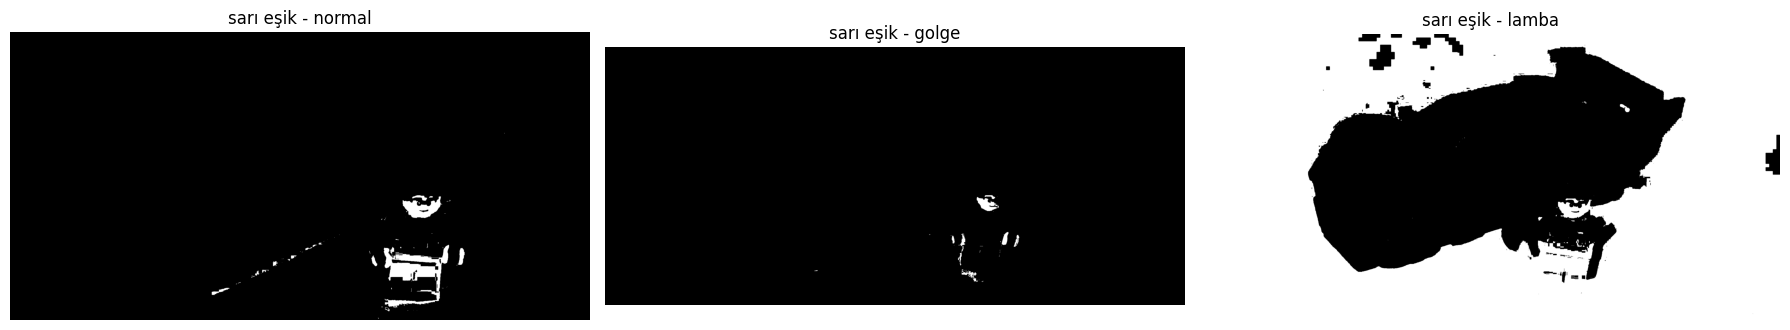

,fotograf,sari_alan_%,yuz_medyan_HSV,zemin_medyan_HSV
0,normal,1.3,"(16, 199, 153)","(26, 37, 150)"
1,golge,0.3,"(16, 199, 152)","(21, 27, 94)"
2,lamba,67.0,"(16, 211, 128)","(19, 82, 159)"


In [ ]:
sari_sonuc = []
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for i, ad in enumerate(DOSYALAR):
    hsv = cv2.cvtColor(bgr[ad], cv2.COLOR_BGR2HSV)
    m = cv2.inRange(hsv, np.array(SARI_ALT), np.array(SARI_UST))
    x, y, w, h = YUZ_ROI[ad]
    zx, zy = PIKSELLER[ad][0]
    zemin = hsv[zy-10:zy+11, zx-10:zx+11].reshape(-1, 3)
    sari_sonuc.append({"fotograf": ad,
                       "sari_alan_%": round(100*np.count_nonzero(m)/m.size, 1),
                       "yuz_medyan_HSV": tuple(int(v) for v in np.median(hsv[y:y+h, x:x+w].reshape(-1, 3), axis=0)),
                       "zemin_medyan_HSV": tuple(int(v) for v in np.median(zemin, axis=0))})
    ax[i].imshow(m, cmap="gray"); ax[i].set_title(f"sarı eşik - {ad}"); ax[i].axis("off")
plt.tight_layout()
plt.savefig("sonuclar/sari_esik.png", dpi=120)
plt.show()
sari_tablo = pd.DataFrame(sari_sonuc)
sari_tablo.to_csv("sonuclar/sari_esik.csv", index=False)
sari_tablo

## 3. Parlaklık ve gama

In [13]:
def parlaklik(I, b):
    J = I.astype(np.float64) + b
    return np.clip(J, 0, 255)

def gama(I, g):
    J = 255.0 * (I.astype(np.float64) / 255.0) ** g
    return np.clip(J, 0, 255)

print("64 -> gama 0.5:", gama(np.array([64]), 0.5)[0].round(1))
print("64 -> gama 2.0:", gama(np.array([64]), 2.0)[0].round(1))

64 -> gama 0.5: 127.7
64 -> gama 2.0: 16.1


In [14]:
I = rgb["normal"]
ort0 = I.astype(np.float64).mean()

donusumler = {f"parlaklik b=+{B_KAYMA}": parlaklik(I, B_KAYMA)}
for g in GAMALAR:
    donusumler[f"gama {g}"] = gama(I, g)

sonuc = [{"donusum": "orijinal", "ortalama": round(ort0, 2), "basit_beklenti": "-",
          "255'te_kirpilan_%": round(100 * np.mean(I == 255), 2)}]
for ad, J in donusumler.items():
    if ad.startswith("parlaklik"):
        beklenti = ort0 + B_KAYMA
        kirpilan = 100 * np.mean(I.astype(int) + B_KAYMA > 255)
    else:
        g = float(ad.split()[1])
        beklenti = 255 * (ort0 / 255) ** g
        kirpilan = 100 * np.mean(J >= 255)
    sonuc.append({"donusum": ad, "ortalama": round(J.mean(), 2),
                  "basit_beklenti": round(beklenti, 2), "255'te_kirpilan_%": round(kirpilan, 2)})

donusum_tablo = pd.DataFrame(sonuc)
donusum_tablo.to_csv("sonuclar/parlaklik_gama.csv", index=False)
donusum_tablo

,donusum,ortalama,basit_beklenti,255'te_kirpilan_%
0,orijinal,91.78,-,0.00
1,parlaklik b=+40,131.77,131.78,0.04
2,gama 0.5,145.12,152.98,0.00
3,gama 2.0,41.96,33.03,0.00


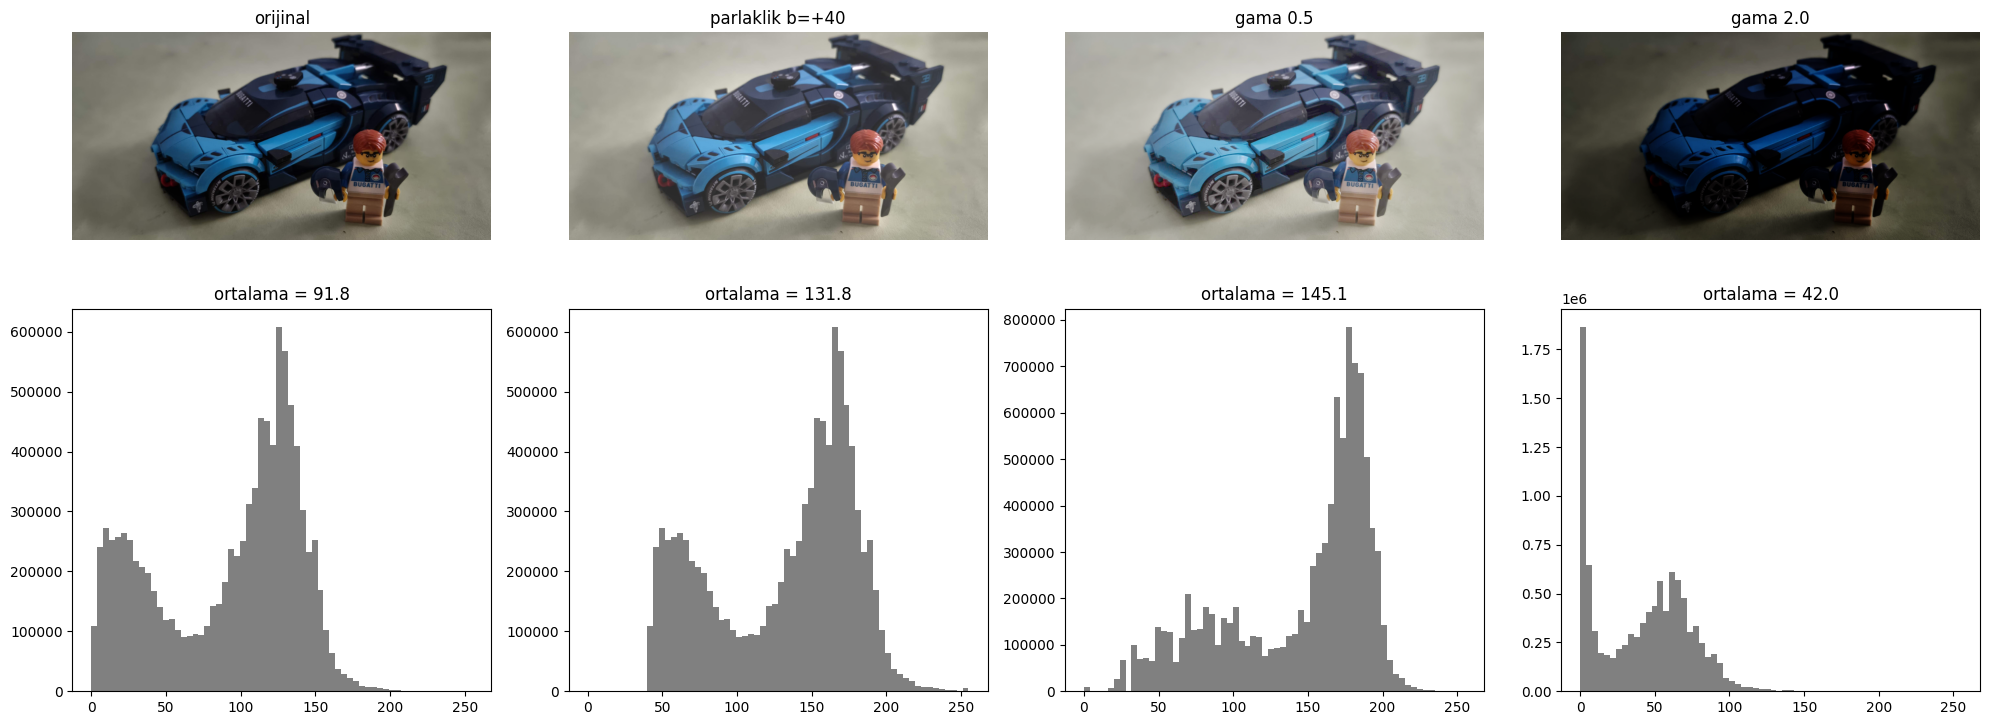

In [15]:
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
gorseller = {"orijinal": I.astype(np.float64), **donusumler}
for i, (ad, J) in enumerate(gorseller.items()):
    ax[0, i].imshow(J.astype(np.uint8)); ax[0, i].set_title(ad); ax[0, i].axis("off")
    ax[1, i].hist(J.ravel(), bins=64, range=(0, 255), color="gray")
    ax[1, i].set_title(f"ortalama = {J.mean():.1f}")
plt.tight_layout()
plt.savefig("sonuclar/parlaklik_gama.png", dpi=120)
plt.show()

## 4. Küçültmenin etkisi

In [ ]:
x, y, w, h = YAZI_BOLGE
kesit = rgb["normal"][y:y+h, x:x+w]
kw, kh = w // OLCEK, h // OLCEK

kucuk_nearest = cv2.resize(kesit, (kw, kh), interpolation=cv2.INTER_NEAREST)
kucuk_area    = cv2.resize(kesit, (kw, kh), interpolation=cv2.INTER_AREA)

buyuk_nearest = cv2.resize(kucuk_nearest, (w, h), interpolation=cv2.INTER_NEAREST)
buyuk_area    = cv2.resize(kucuk_area,    (w, h), interpolation=cv2.INTER_NEAREST)
buyuk_area_cubic = np.clip(cv2.resize(kucuk_area, (w, h), interpolation=cv2.INTER_CUBIC), 0, 255)

print("Kesit boyutu   :", kesit.shape)
print("Küçük boyut    :", kucuk_area.shape)

fark = []
for ad, J in [("INTER_NEAREST", buyuk_nearest), ("INTER_AREA", buyuk_area),
              ("INTER_AREA + INTER_CUBIC büyütme", buyuk_area_cubic)]:
    mae = np.abs(J.astype(float) - kesit.astype(float)).mean()
    fark.append({"yontem": ad, "kucuk_boyut": f"{kw}x{kh}", "ortalama_mutlak_fark": round(mae, 2)})
kucultme_tablo = pd.DataFrame(fark)
kucultme_tablo.to_csv("sonuclar/kucultme.csv", index=False)
kucultme_tablo

Kesit boyutu   : (100, 240, 3)
Küçük boyut    : (25, 60, 3)


,yontem,kucuk_boyut,ortalama_mutlak_fark
0,INTER_NEAREST,60x25,7.50
1,INTER_AREA,60x25,5.10
2,INTER_AREA + INTER_CUBIC büyütme,60x25,3.74


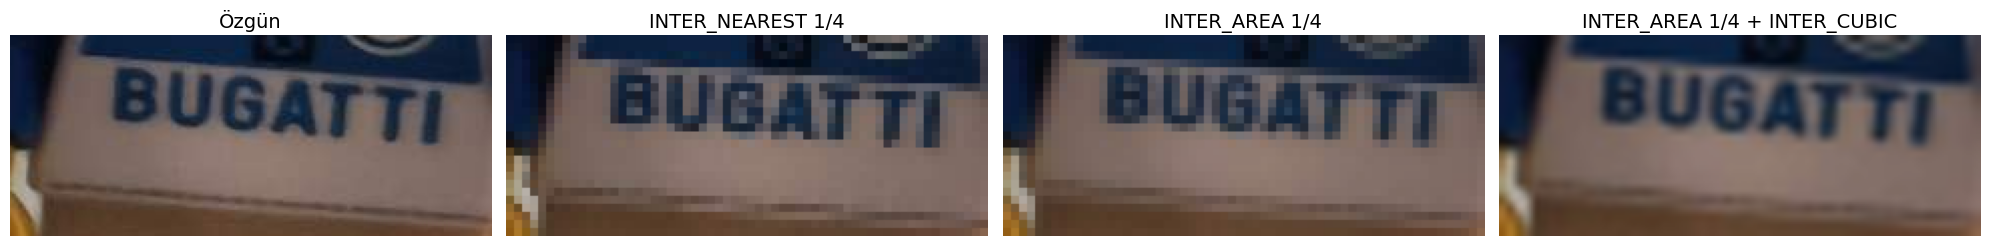

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(20, 3.2))
for a, (baslik, J) in zip(ax, [("Özgün", kesit),
                               (f"INTER_NEAREST 1/{OLCEK}", buyuk_nearest),
                               (f"INTER_AREA 1/{OLCEK}", buyuk_area),
                               (f"INTER_AREA 1/{OLCEK} + INTER_CUBIC", buyuk_area_cubic)]):
    a.imshow(J); a.set_title(baslik, fontsize=14); a.axis("off")
plt.tight_layout()
plt.savefig("sonuclar/kucultme_karsilastirma.png", dpi=120)
plt.show()

## 5. Sonuç tablosu

In [ ]:
with open("sonuclar/sonuc_tablosu.csv", "w", encoding="utf-8") as f:
    for baslik, df in [("PIKSEL DEGERLERI", piksel_tablo), ("MASKE ORANLARI", maske_tablo),
                       ("PARLAKLIK VE GAMA", donusum_tablo), ("V ALT SINIRI 40 DENEMESI", v40_tablo),
                       ("SARI ESIK", sari_tablo), ("KUCULTME", kucultme_tablo)]:
        f.write(f"# {baslik}\n")
        df.to_csv(f, index=False)
        f.write("\n")

param = {"DOSYALAR": DOSYALAR, "PIKSELLER": PIKSELLER, "NESNE_ROI": NESNE_ROI, "ARABA_KUTU": ARABA_KUTU, "YUZ_ROI": YUZ_ROI,
         "RGB_ALT": RGB_ALT, "RGB_UST": RGB_UST, "HSV_ALT": HSV_ALT, "HSV_UST": HSV_UST, "SARI_ALT": SARI_ALT, "SARI_UST": SARI_UST,
         "B_KAYMA": B_KAYMA, "GAMALAR": GAMALAR, "YAZI_BOLGE": YAZI_BOLGE, "OLCEK": OLCEK}
with open("sonuclar/parametreler.txt", "w", encoding="utf-8") as f:
    for k, v in param.items():
        f.write(f"{k} = {v}\n")

print("Kaydedilen dosyalar:")
for d in sorted(os.listdir("sonuclar")):
    print("  sonuclar/" + d)

Kaydedilen dosyalar:
  sonuclar/alti_maske.png
  sonuclar/kucultme.csv
  sonuclar/kucultme_karsilastirma.png
  sonuclar/maske_hsv_golge.png
  sonuclar/maske_hsv_lamba.png
  sonuclar/maske_hsv_normal.png
  sonuclar/maske_oranlari.csv
  sonuclar/maske_rgb_golge.png
  sonuclar/maske_rgb_lamba.png
  sonuclar/maske_rgb_normal.png
  sonuclar/ozgun_fotograflar.png
  sonuclar/parametreler.txt
  sonuclar/parlaklik_gama.csv
  sonuclar/parlaklik_gama.png
  sonuclar/piksel_degerleri.csv
  sonuclar/sari_esik.csv
  sonuclar/sari_esik.png
  sonuclar/sonuc_tablosu.csv


## Yapay zekâ beyanı

Kodlama desteği için Claude kullandım.